# Lab 1 — Indic Language Identification

This notebook implements the assignment using IndicCorpV2: construct a balanced 23-language sentence dataset, build custom TF-IDF features, train a custom softmax logistic-regression classifier, and evaluate with custom macro-F1.

The assignment specifies 1000 sentences per language, an 80:10:10 stratified split, word 1/2-grams plus character 2/3/4-grams, and no predefined sklearn classes for TF-IDF, logistic regression, or evaluation.


In this section, we construct the dataset without using the Hugging Face Datasets API. The notebook downloads the required corpus text files directly, which avoids the `429 Too Many Requests` API-tree error.


In [1]:
# Dependencies and reproducibility
import re
import random
import csv
import os
import math
import time
from collections import defaultdict, Counter
from typing import List, Tuple, Optional

import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
import requests

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Set True for a quick pipeline smoke-test (100 sentences/language).
# Set False for the actual assignment (1000 sentences/language).
FAST_MODE = False

print("Setup completed successfully.")
print("Using direct file downloads instead of the Hugging Face Datasets API.")
print("This avoids the 429 Too Many Requests error caused by repeated API tree requests.")


Setup completed successfully.
Using direct file downloads instead of the Hugging Face Datasets API.
This avoids the 429 Too Many Requests error caused by repeated API tree requests.


In [2]:
# IndicCorpV2 language labels required by the assignment.
# The repository README maps these labels to the underlying corpus files.
LANGUAGE_CONFIGS = [
    "asm_Beng", "ben_Beng", "brx_Deva", "doi_Deva", "gom_Deva", "guj_Gujr",
    "hin_Deva", "kan_Knda", "kas_Arab", "mai_Deva", "mal_Mlym", "mar_Deva",
    "mni_Mtei", "npi_Deva", "ory_Orya", "pan_Guru", "san_Deva", "snd_Deva",
    "tam_Taml", "tel_Telu", "urd_Arab", "khasi", "santhali"
]

# These are the actual file names documented by IndicCorpV2.
LANG_TO_FILE = {
    "asm_Beng": "as.txt",
    "ben_Beng": "bn.txt",
    "brx_Deva": "bd.txt",
    "doi_Deva": "dg.txt",
    "gom_Deva": "gom.txt",
    "guj_Gujr": "gu.txt",
    "hin_Deva": "hi.txt",       # fallback below also tries hi-*.txt
    "kan_Knda": "kn.txt",
    "kas_Arab": "ks.txt",
    "mai_Deva": "mai.txt",
    "mal_Mlym": "ml.txt",
    "mar_Deva": "mr.txt",
    "mni_Mtei": "mni.txt",
    "npi_Deva": "ne.txt",
    "ory_Orya": "or.txt",
    "pan_Guru": "pa.txt",
    "san_Deva": "sa.txt",
    "snd_Deva": "sd.txt",
    "tam_Taml": "ta.txt",
    "tel_Telu": "te.txt",
    "urd_Arab": "ur.txt",
    "khasi": "kha.txt",
    "santhali": "sat.txt",
}

# Primary source: direct Hugging Face file download. This does NOT call the
# Hugging Face /api/datasets/... tree endpoint, so it avoids the 429 error.
HF_RAW_BASE = "https://huggingface.co/datasets/ai4bharat/IndicCorpV2/resolve/main/data/"

# Fallback source used by the original IndicCorpV2 dataset loader. It is the
# frozen IndicCorpV2 corpus released for the paper and also avoids the HF API.
OBJECTSTORE_BASE = (
    "https://objectstore.e2enetworks.net/"
    "ai4b-public-nlu-nlg/indic-corp-frozen-for-the-paper-oct-2022/"
)

TARGET_PER_LANGUAGE = 100 if FAST_MODE else 1000

SENT_BOUNDARY = re.compile(r"(?<=[.?!\u0964\u0965\u06D4])\s+")

def tokenize_sentences(
    paragraph: str,
    min_words: int = 3,
    min_len: int = 10,
    max_len: int = 500
) -> List[str]:
    """Split a corpus paragraph into usable sentences."""
    paragraph = re.sub(r"\s+", " ", (paragraph or "").strip())
    if not paragraph:
        return []

    sentences = []
    for part in SENT_BOUNDARY.split(paragraph):
        part = part.strip()
        if min_len <= len(part) <= max_len and len(part.split()) >= min_words:
            sentences.append(part)
    return sentences


def _candidate_urls(label: str) -> List[str]:
    """Return direct-download URLs without using the Hugging Face API."""
    filename = LANG_TO_FILE[label]
    urls = [HF_RAW_BASE + filename]

    # Current IndicCorpV2 README uses data/hi-*.txt for Hindi. Try likely
    # shards if hi.txt is not present. We stop as soon as enough sentences are found.
    if label == "hin_Deva":
        urls.extend(HF_RAW_BASE + f"hi-{i}.txt" for i in range(1, 11))

    # Fallback to the original frozen corpus URL.
    code = filename.rsplit(".", 1)[0]
    urls.append(OBJECTSTORE_BASE + code + ".txt")
    return urls


def _collect_from_url(url: str, selected: List[str], seen: set, target: int) -> bool:
    """Stream a text file and extract sentences until target is reached."""
    try:
        with requests.get(
            url,
            stream=True,
            timeout=(20, 120),
            headers={"User-Agent": "Mozilla/5.0 LID-Lab-Assignment"},
        ) as response:
            if response.status_code != 200:
                return False
            response.raise_for_status()

            # The corpus is line-oriented: each line is a paragraph/document.
            for raw_line in response.iter_lines(decode_unicode=True):
                if raw_line is None:
                    continue
                for sentence in tokenize_sentences(raw_line):
                    if sentence not in seen:
                        seen.add(sentence)
                        selected.append(sentence)
                        if len(selected) >= target:
                            return True
    except (requests.RequestException, UnicodeError) as exc:
        print(f"\n  download failed: {type(exc).__name__}")
    return False


def collect_and_build_dataset(
    target_per_lang: int = TARGET_PER_LANGUAGE,
    seed: int = RANDOM_SEED
) -> List[Tuple[str, str]]:
    """Collect exactly target_per_lang unique sentences for every language."""
    all_data = []
    rng = random.Random(seed)

    for lang in LANGUAGE_CONFIGS:
        print(f"Collecting {lang} ...", end=" ", flush=True)
        seen = set()
        selected = []

        for url in _candidate_urls(lang):
            if len(selected) >= target_per_lang:
                break
            source_name = "Hugging Face direct file" if "huggingface.co" in url else "objectstore fallback"
            print(f"\n    trying {source_name}: {url.split('/')[-1]}", end="", flush=True)
            _collect_from_url(url, selected, seen, target_per_lang)

        if len(selected) < target_per_lang:
            raise RuntimeError(
                f"Could collect only {len(selected)} unique sentences for {lang}; "
                f"needed {target_per_lang}.\n"
                "If Hugging Face is temporarily rate-limited, wait a few minutes "
                "or set HF_TOKEN if your environment requires authentication."
            )

        rng.shuffle(selected)
        selected = selected[:target_per_lang]
        all_data.extend((sentence, lang) for sentence in selected)
        print(f"\n    collected {len(selected)} sentences")

    rng.shuffle(all_data)
    return all_data

print(f"Languages: {len(LANGUAGE_CONFIGS)}")
print(f"Target sentences per language: {TARGET_PER_LANGUAGE}")


Languages: 23
Target sentences per language: 1000


In [3]:
CSV_PATH = "data/sentences.csv"
EXPECTED_TOTAL = len(LANGUAGE_CONFIGS) * TARGET_PER_LANGUAGE

def load_cached_dataset(path: str):
    if not os.path.exists(path) or os.path.getsize(path) <= 100:
        return None

    rows = []
    with open(path, "r", encoding="utf-8", newline="") as f:
        reader = csv.DictReader(f)
        if reader.fieldnames != ["text", "label"]:
            return None
        for row in reader:
            text = (row.get("text") or "").strip()
            label = (row.get("label") or "").strip()
            if text and label:
                rows.append((text, label))

    counts = Counter(label for _, label in rows)
    valid = (
        len(rows) == EXPECTED_TOTAL
        and set(counts) == set(LANGUAGE_CONFIGS)
        and all(counts[label] == TARGET_PER_LANGUAGE for label in LANGUAGE_CONFIGS)
    )
    return rows if valid else None

raw_dataset = load_cached_dataset(CSV_PATH)

# A valid local cache is preferred, so the corpus is downloaded only once.

if raw_dataset is not None:
    print(f"Loaded valid cached dataset: {len(raw_dataset)} sentences.")
else:
    print("No valid cache found. Downloading and constructing the dataset...")
    os.makedirs("data", exist_ok=True)
    raw_dataset = collect_and_build_dataset()

    with open(CSV_PATH, "w", encoding="utf-8", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["text", "label"])
        writer.writerows(raw_dataset)

    print(f"Saved {len(raw_dataset)} sentences to {CSV_PATH}")

print("Label counts:")
for label in LANGUAGE_CONFIGS:
    print(f"  {label:<12} {sum(y == label for _, y in raw_dataset)}")


No valid cache found. Downloading and constructing the dataset...
    trying Hugging Face direct file: as.txt
    collected 1000 sentences
    trying Hugging Face direct file: bn.txt
    collected 1000 sentences
    trying Hugging Face direct file: bd.txt
    collected 1000 sentences
    trying Hugging Face direct file: dg.txt
    collected 1000 sentences
    trying Hugging Face direct file: gom.txt
    collected 1000 sentences
    trying Hugging Face direct file: gu.txt
    collected 1000 sentences
    trying Hugging Face direct file: hi.txt
    trying Hugging Face direct file: hi-1.txt
    collected 1000 sentences
    trying Hugging Face direct file: kn.txt
    collected 1000 sentences
    trying Hugging Face direct file: ks.txt
    collected 1000 sentences
    trying Hugging Face direct file: mai.txt
    collected 1000 sentences
    trying Hugging Face direct file: ml.txt
    collected 1000 sentences
    trying Hugging Face direct file: mr.txt
    collected 1000 sentences
    trying

In [ ]:
def perform_stratified_split(
    data: List[Tuple[str, str]],
    train_ratio: float = 0.8,
    val_ratio: float = 0.1,
    seed: int = RANDOM_SEED
):
    
    if not math.isclose(train_ratio + val_ratio, 0.9):
        raise ValueError("train_ratio + val_ratio must be 0.9 for an 80/10/10 split.")

    rng = random.Random(seed)
    by_label = defaultdict(list)
    for text, label in data:
        by_label[label].append(text)

    train_data, val_data, test_data = [], [], []

    for label in LANGUAGE_CONFIGS:
        texts = list(by_label[label])
        if len(texts) != TARGET_PER_LANGUAGE:
            raise ValueError(
                f"{label} has {len(texts)} samples; expected {TARGET_PER_LANGUAGE}."
            )
        rng.shuffle(texts)

        n = len(texts)
        n_train = int(round(n * train_ratio))
        n_val = int(round(n * val_ratio))

        train_data.extend((t, label) for t in texts[:n_train])
        val_data.extend((t, label) for t in texts[n_train:n_train + n_val])
        test_data.extend((t, label) for t in texts[n_train + n_val:])

    rng.shuffle(train_data)
    rng.shuffle(val_data)
    rng.shuffle(test_data)
    return train_data, val_data, test_data

train_set, val_set, test_set = perform_stratified_split(raw_dataset)

train_texts, train_labels = zip(*train_set)
val_texts, val_labels = zip(*val_set)
test_texts, test_labels = zip(*test_set)

classes = list(LANGUAGE_CONFIGS)
label_to_idx = {label: i for i, label in enumerate(classes)}
idx_to_label = {i: label for i, label in enumerate(classes)}

y_train = np.array([label_to_idx[label] for label in train_labels], dtype=np.int32)
y_val = np.array([label_to_idx[label] for label in val_labels], dtype=np.int32)
y_test = np.array([label_to_idx[label] for label in test_labels], dtype=np.int32)

print(f"Train: {len(train_set)} | Validation: {len(val_set)} | Test: {len(test_set)}")
print(f"{'Language':<15} | {'Train':<6} | {'Val':<6} | {'Test':<6}")
print("-" * 50)

train_counts = Counter(train_labels)
val_counts = Counter(val_labels)
test_counts = Counter(test_labels)

for label in classes:
    print(
        f"{label:<15} | {train_counts[label]:<6} | "
        f"{val_counts[label]:<6} | {test_counts[label]:<6}"
    )


Train: 18400 | Validation: 2300 | Test: 2300
Language        | Train  | Val    | Test  
--------------------------------------------------
asm_Beng        | 800    | 100    | 100   
ben_Beng        | 800    | 100    | 100   
brx_Deva        | 800    | 100    | 100   
doi_Deva        | 800    | 100    | 100   
gom_Deva        | 800    | 100    | 100   
guj_Gujr        | 800    | 100    | 100   
hin_Deva        | 800    | 100    | 100   
kan_Knda        | 800    | 100    | 100   
kas_Arab        | 800    | 100    | 100   
mai_Deva        | 800    | 100    | 100   
mal_Mlym        | 800    | 100    | 100   
mar_Deva        | 800    | 100    | 100   
mni_Mtei        | 800    | 100    | 100   
npi_Deva        | 800    | 100    | 100   
ory_Orya        | 800    | 100    | 100   
pan_Guru        | 800    | 100    | 100   
san_Deva        | 800    | 100    | 100   
snd_Deva        | 800    | 100    | 100   
tam_Taml        | 800    | 100    | 100   
tel_Telu        | 800    | 100    | 100   
u

## Section 2 — Custom TF-IDF Vectorizer
Here we implement `CustomTfidfVectorizer` from scratch. Key features:
- Word Unigrams + Bigrams prefixed with `W1::` and `W2::`.
- Character 2-gram, 3-gram, and 4-grams prefixed with `C2::`, `C3::`, `C4::`.
- Supports vocabulary pruning based on `min_df`.
- Computes Term Frequency (TF) using sublinear TF (`1 + log(tf)`).
- Computes Document Frequency and IDF (`log((1 + N) / (1 + df)) + 1`).
- Row-normalizes the output using L2 norm to facilitate training convergence.

In [5]:
class CustomTfidfVectorizer:
    """TF-IDF vectorizer implemented from scratch using scipy sparse matrices."""

    def __init__(self, min_df: int = 2, max_features: Optional[int] = 100000):
        self.min_df = min_df
        self.max_features = max_features
        self.vocab = {}
        self.idf = None
        self.n_docs = 0

    def _get_word_ngrams(self, text: str) -> List[str]:
        words = text.lower().split()
        grams = [f"W1::{word}" for word in words]
        grams.extend(
            f"W2::{words[i]} {words[i + 1]}"
            for i in range(len(words) - 1)
        )
        return grams

    def _get_char_ngrams(self, text: str) -> List[str]:
        # Add boundary spaces so character n-grams capture word beginnings/endings.
        processed = " " + " ".join(text.lower().split()) + " "
        grams = []
        for n in (2, 3, 4):
            grams.extend(
                f"C{n}::{processed[i:i+n]}"
                for i in range(len(processed) - n + 1)
            )
        return grams

    def _get_all_ngrams(self, text: str) -> List[str]:
        return self._get_word_ngrams(text) + self._get_char_ngrams(text)

    def fit(self, texts: List[str]):
        self.n_docs = len(texts)
        if self.n_docs == 0:
            raise ValueError("Cannot fit TF-IDF on an empty corpus.")

        doc_freqs = defaultdict(int)

        for text in texts:
            for gram in set(self._get_all_ngrams(text)):
                doc_freqs[gram] += 1

        filtered = [gram for gram, df in doc_freqs.items() if df >= self.min_df]
        filtered.sort(key=lambda gram: (-doc_freqs[gram], gram))

        if self.max_features is not None:
            filtered = filtered[:self.max_features]

        self.vocab = {gram: idx for idx, gram in enumerate(filtered)}

        self.idf = np.array(
            [
                math.log((1.0 + self.n_docs) / (1.0 + doc_freqs[gram])) + 1.0
                for gram in filtered
            ],
            dtype=np.float32
        )
        return self

    def transform(self, texts: List[str]) -> sp.csr_matrix:
        if self.idf is None:
            raise RuntimeError("Call fit() before transform().")

        rows, cols, vals = [], [], []

        for row_idx, text in enumerate(texts):
            counts = Counter(self._get_all_ngrams(text))

            for gram, count in counts.items():
                col_idx = self.vocab.get(gram)
                if col_idx is None:
                    continue

                tf = 1.0 + math.log(count)
                value = tf * float(self.idf[col_idx])

                rows.append(row_idx)
                cols.append(col_idx)
                vals.append(value)

        matrix = sp.csr_matrix(
            (np.asarray(vals, dtype=np.float32), (rows, cols)),
            shape=(len(texts), len(self.vocab)),
            dtype=np.float32
        )

        # Row-wise L2 normalization.
        norms = np.sqrt(matrix.multiply(matrix).sum(axis=1)).A1
        nonzero = norms > 0
        if np.any(nonzero):
            inv_norms = np.zeros_like(norms, dtype=np.float32)
            inv_norms[nonzero] = 1.0 / norms[nonzero]
            matrix = sp.diags(inv_norms).dot(matrix).tocsr()

        return matrix

    def fit_transform(self, texts: List[str]) -> sp.csr_matrix:
        return self.fit(texts).transform(texts)


In [6]:
toy_texts = [
    "यह हिंदी वाक्य है।",
    "இது தமிழ் வாக்கியம்.",
    "यह दूसरा हिंदी वाक्य है।"
]
toy_vec = CustomTfidfVectorizer(min_df=1, max_features=100)
toy_vec.fit(toy_texts)
toy_transformed = toy_vec.transform(toy_texts)
print("Sanity Check: Matrix Shape:", toy_transformed.shape)
print("Sample features:", list(toy_vec.vocab.keys())[:10])

Sanity Check: Matrix Shape: (3, 100)
Sample features: ['C2:: य', 'C2:: व', 'C2:: ह', 'C2::ंद', 'C2::क्', 'C2::दी', 'C2::य ', 'C2::यह', 'C2::वा', 'C2::ह ']


## Section 3 — Custom Softmax Logistic Regression
Here we implement `SoftmaxLogisticRegression` using numpy. 
- **Softmax calculation**: Numerically stable (shift logits by maximum value).
- **Optimisation**: Mini-batch Gradient Descent with step learning rate decay.
- **Regularisation**: L2 regularisation.
- **Val Loss / F1 Tracker**: Prints validation progress epoch by epoch.
- **Early Stopping**: Reverts and keeps the best weights if validation Macro-F1 does not improve after a few epochs.

In [7]:
class SoftmaxLogisticRegression:
    """Multiclass softmax logistic regression implemented from scratch with NumPy."""

    def __init__(
        self,
        lr: float = 0.5,
        epochs: int = 50,
        batch_size: int = 128,
        lambda_reg: float = 1e-4,
        lr_decay_step: int = 10,
        lr_decay_rate: float = 0.5,
        early_stopping_patience: int = 5,
        random_state: int = RANDOM_SEED
    ):
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.lambda_reg = lambda_reg
        self.lr_decay_step = lr_decay_step
        self.lr_decay_rate = lr_decay_rate
        self.early_stopping_patience = early_stopping_patience
        self.random_state = random_state
        self.W = None
        self.b = None
        self.history = []

    @staticmethod
    def _softmax(logits: np.ndarray) -> np.ndarray:
        shifted = logits - np.max(logits, axis=1, keepdims=True)
        exps = np.exp(shifted)
        return exps / np.sum(exps, axis=1, keepdims=True)

    def fit(self, X_train, y_train, X_val, y_val):
        rng = np.random.RandomState(self.random_state)
        n_samples, n_features = X_train.shape
        n_classes = int(np.max(y_train)) + 1

        scale = 1.0 / np.sqrt(max(n_features, 1))
        self.W = (rng.randn(n_classes, n_features) * scale).astype(np.float32)
        self.b = np.zeros(n_classes, dtype=np.float32)

        best_f1 = -1.0
        best_W = self.W.copy()
        best_b = self.b.copy()
        patience_counter = 0
        current_lr = self.lr

        for epoch in range(1, self.epochs + 1):
            if epoch > 1 and self.lr_decay_step > 0 and epoch % self.lr_decay_step == 0:
                current_lr *= self.lr_decay_rate

            indices = rng.permutation(n_samples)

            for start in range(0, n_samples, self.batch_size):
                batch_idx = indices[start:start + self.batch_size]
                X_batch = X_train[batch_idx]
                y_batch = y_train[batch_idx]

                logits = X_batch.dot(self.W.T) + self.b
                probs = self._softmax(logits)

                # Gradient of cross-entropy loss.
                probs[np.arange(len(y_batch)), y_batch] -= 1.0
                probs /= len(y_batch)

                # IMPORTANT: dense @ sparse returns a dense ndarray.
                dW = np.asarray(X_batch.T.dot(probs).T, dtype=np.float32)
                db = probs.sum(axis=0).astype(np.float32)

                # L2 regularization on weights, not bias.
                dW += self.lambda_reg * self.W

                self.W -= current_lr * dW
                self.b -= current_lr * db

            val_preds = self.predict(X_val)
            val_f1 = calculate_macro_f1(y_val, val_preds)

            val_logits = X_val.dot(self.W.T) + self.b
            val_probs = self._softmax(val_logits)
            val_loss = (
                -np.mean(np.log(val_probs[np.arange(len(y_val)), y_val] + 1e-15))
                + 0.5 * self.lambda_reg * np.sum(self.W ** 2)
            )

            self.history.append((epoch, val_loss, val_f1, current_lr))

            if epoch == 1 or epoch % 5 == 0:
                print(
                    f"Epoch {epoch:2d}/{self.epochs} | "
                    f"Val Loss: {val_loss:.4f} | "
                    f"Val Macro-F1: {val_f1:.4f} | "
                    f"lr: {current_lr:.4f}"
                )

            if val_f1 > best_f1 + 1e-8:
                best_f1 = val_f1
                best_W = self.W.copy()
                best_b = self.b.copy()
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= self.early_stopping_patience:
                    print(f"Early stopping at epoch {epoch}; restoring best weights.")
                    break

        self.W = best_W
        self.b = best_b
        return self

    def predict_proba(self, X):
        return self._softmax(X.dot(self.W.T) + self.b)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1).astype(np.int32)


## Section 4 — Custom Evaluation Metrics
In this section, we implement custom metrics for evaluation:
- `confusion_matrix`: Computes raw confusion counts between actual and predicted labels.
- `classification_report`: Computes precision, recall, and F1 per class from the confusion matrix.
- `calculate_macro_f1`: Computes macro-averaged F1 directly.
- **Toy Check**: Runs a sanity verification on a small test case to verify metric correctness.

In [8]:
def compute_confusion_matrix(y_true: np.ndarray, y_pred: np.ndarray, num_classes: int) -> np.ndarray:
    cm = np.zeros((num_classes, num_classes), dtype=np.int32)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm

def calculate_macro_f1(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    classes_in_data = np.unique(np.concatenate([y_true, y_pred]))
    n_classes = len(classes_in_data)
    if n_classes == 0:
        return 0.0
    
    # Find the overall max label index to size the confusion matrix
    max_lbl = int(np.max(np.concatenate([y_true, y_pred])))
    cm = compute_confusion_matrix(y_true, y_pred, max_lbl + 1)
    
    f1_scores = []
    for c in classes_in_data:
        TP = cm[c, c]
        FP = cm[:, c].sum() - TP
        FN = cm[c, :].sum() - TP
        
        prec = TP / (TP + FP) if (TP + FP) > 0 else 0.0
        rec = TP / (TP + FN) if (TP + FN) > 0 else 0.0
        
        f1 = (2.0 * prec * rec) / (prec + rec) if (prec + rec) > 0.0 else 0.0
        f1_scores.append(f1)
        
    return float(np.mean(f1_scores))

# --- Toy Example Sanity Check ---
toy_true = np.array([0, 1, 2, 0, 1, 2])
toy_pred = np.array([0, 2, 2, 0, 1, 1])
print("Toy Example Macro F1:", calculate_macro_f1(toy_true, toy_pred))

Toy Example Macro F1: 0.6666666666666666


## Section 3 (Continued) — Hyperparameter Tuning
We fit our custom vectorizer on the training texts, construct TF-IDF matrices, and sweep over a grid of hyperparameters (learning rate, L2 regularization strength) to find the best configuration on our validation set.

In [9]:
print("Building TF-IDF matrices...")
MAX_FEATURES = 60000 if FAST_MODE else 120000
vectorizer = CustomTfidfVectorizer(min_df=2, max_features=MAX_FEATURES)
vectorizer.fit(train_texts)

X_train = vectorizer.transform(train_texts)
X_val = vectorizer.transform(val_texts)
X_test = vectorizer.transform(test_texts)

print(f"Vocabulary size: {len(vectorizer.vocab)}")
print(f"X_train shape: {X_train.shape}")
print(f"X_val shape:   {X_val.shape}")
print(f"X_test shape:  {X_test.shape}")

# Hyperparameter search is performed without sklearn.
learning_rates = [0.2, 0.5, 0.8]
lambda_regs = [1e-5, 1e-4, 1e-3]

tune_epochs = 5 if FAST_MODE else 15
best_hyper_f1 = -1.0
best_params = None

print("\n--- Hyperparameter Search ---")
for lr in learning_rates:
    for lam in lambda_regs:
        print(f"Testing lr={lr}, lambda={lam}")
        clf = SoftmaxLogisticRegression(
            lr=lr,
            epochs=tune_epochs,
            batch_size=256,
            lambda_reg=lam,
            early_stopping_patience=3,
            random_state=RANDOM_SEED
        )
        clf.fit(X_train, y_train, X_val, y_val)
        val_preds = clf.predict(X_val)
        score = calculate_macro_f1(y_val, val_preds)
        print(f"Validation Macro-F1: {score:.4f}\n")

        if score > best_hyper_f1:
            best_hyper_f1 = score
            best_params = {"lr": lr, "lambda_reg": lam}

print(f"Best parameters: {best_params}")
print(f"Best validation Macro-F1: {best_hyper_f1:.4f}")


Building TF-IDF matrices...
Vocabulary size: 86466
X_train shape: (18400, 86466)
X_val shape:   (2300, 86466)
X_test shape:  (2300, 86466)

--- Hyperparameter Search ---
Testing lr=0.2, lambda=1e-05
Epoch  1/15 | Val Loss: 2.9610 | Val Macro-F1: 0.8252 | lr: 0.2000
Epoch  5/15 | Val Loss: 2.3432 | Val Macro-F1: 0.8356 | lr: 0.2000
Epoch 10/15 | Val Loss: 1.8319 | Val Macro-F1: 0.8578 | lr: 0.1000
Epoch 15/15 | Val Loss: 1.6284 | Val Macro-F1: 0.8627 | lr: 0.1000
Validation Macro-F1: 0.8627

Testing lr=0.2, lambda=0.0001
Epoch  1/15 | Val Loss: 2.9623 | Val Macro-F1: 0.8252 | lr: 0.2000
Epoch  5/15 | Val Loss: 2.3490 | Val Macro-F1: 0.8357 | lr: 0.2000
Epoch 10/15 | Val Loss: 1.8467 | Val Macro-F1: 0.8578 | lr: 0.1000
Epoch 15/15 | Val Loss: 1.6483 | Val Macro-F1: 0.8627 | lr: 0.1000
Validation Macro-F1: 0.8627

Testing lr=0.2, lambda=0.001
Epoch  1/15 | Val Loss: 2.9745 | Val Macro-F1: 0.8252 | lr: 0.2000
Epoch  5/15 | Val Loss: 2.4038 | Val Macro-F1: 0.8359 | lr: 0.2000
Epoch 10/15 | 

## Section 5 — Final Training, Evaluation & Error Analysis
We train a final model on the full training set using the best hyperparameters found, evaluate it on the test set, plot a confusion matrix heat-map, and print the sorted class performance report.

In [10]:
print("Training final model with the best hyperparameters...")

final_clf = SoftmaxLogisticRegression(
    lr=best_params["lr"],
    epochs=20 if FAST_MODE else 60,
    batch_size=128,
    lambda_reg=best_params["lambda_reg"],
    lr_decay_step=15,
    lr_decay_rate=0.5,
    early_stopping_patience=8,
    random_state=RANDOM_SEED
)

final_clf.fit(X_train, y_train, X_val, y_val)

test_preds = final_clf.predict(X_test)
final_test_f1 = calculate_macro_f1(y_test, test_preds)
final_test_acc = float(np.mean(test_preds == y_test))

print("\n" + "=" * 50)
print(f"Final Test Macro-F1 : {final_test_f1:.4f}")
print(f"Final Test Accuracy : {final_test_acc:.4f}")
print("=" * 50)


Training final model with the best hyperparameters...
Epoch  1/60 | Val Loss: 2.3432 | Val Macro-F1: 0.8457 | lr: 0.5000
Epoch  5/60 | Val Loss: 1.0757 | Val Macro-F1: 0.8687 | lr: 0.5000
Epoch 10/60 | Val Loss: 0.7324 | Val Macro-F1: 0.8961 | lr: 0.5000
Epoch 15/60 | Val Loss: 0.6066 | Val Macro-F1: 0.9006 | lr: 0.2500
Epoch 20/60 | Val Loss: 0.5624 | Val Macro-F1: 0.9016 | lr: 0.2500
Epoch 25/60 | Val Loss: 0.5283 | Val Macro-F1: 0.9034 | lr: 0.2500
Epoch 30/60 | Val Loss: 0.5037 | Val Macro-F1: 0.9055 | lr: 0.1250
Epoch 35/60 | Val Loss: 0.4919 | Val Macro-F1: 0.9035 | lr: 0.1250
Early stopping at epoch 38; restoring best weights.

Final Test Macro-F1 : 0.9084
Final Test Accuracy : 0.9091


In [11]:
max_lbl = int(np.max(np.concatenate([y_test, test_preds])))
cm = compute_confusion_matrix(y_test, test_preds, max_lbl + 1)

per_class_f1 = []
for idx, cls_name in idx_to_label.items():
    TP = cm[idx, idx]
    FP = cm[:, idx].sum() - TP
    FN = cm[idx, :].sum() - TP
    
    prec = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    rec = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1 = (2.0 * prec * rec) / (prec + rec) if (prec + rec) > 0.0 else 0.0
    per_class_f1.append((cls_name, f1))

# Sort ascending (worst performing classes first)
per_class_f1.sort(key=lambda x: x[1])

print("Per-Class Performance (Sorted Ascending):\n")
print(f"{'Language':<22} | {'F1-Score':<10}")
print("-" * 35)
for name, f1 in per_class_f1:
    print(f"{name:<22} | {f1:.4f}")

Per-Class Performance (Sorted Ascending):

Language               | F1-Score  
-----------------------------------
gom_Deva               | 0.6111
hin_Deva               | 0.7064
mar_Deva               | 0.7075
brx_Deva               | 0.7356
mai_Deva               | 0.7570
doi_Deva               | 0.7900
npi_Deva               | 0.8272
san_Deva               | 0.9143
kas_Arab               | 0.9424
urd_Arab               | 0.9569
khasi                  | 0.9804
asm_Beng               | 0.9900
ben_Beng               | 0.9900
mni_Mtei               | 0.9950
ory_Orya               | 0.9950
snd_Deva               | 0.9950
guj_Gujr               | 1.0000
kan_Knda               | 1.0000
mal_Mlym               | 1.0000
pan_Guru               | 1.0000
tam_Taml               | 1.0000
tel_Telu               | 1.0000
santhali               | 1.0000


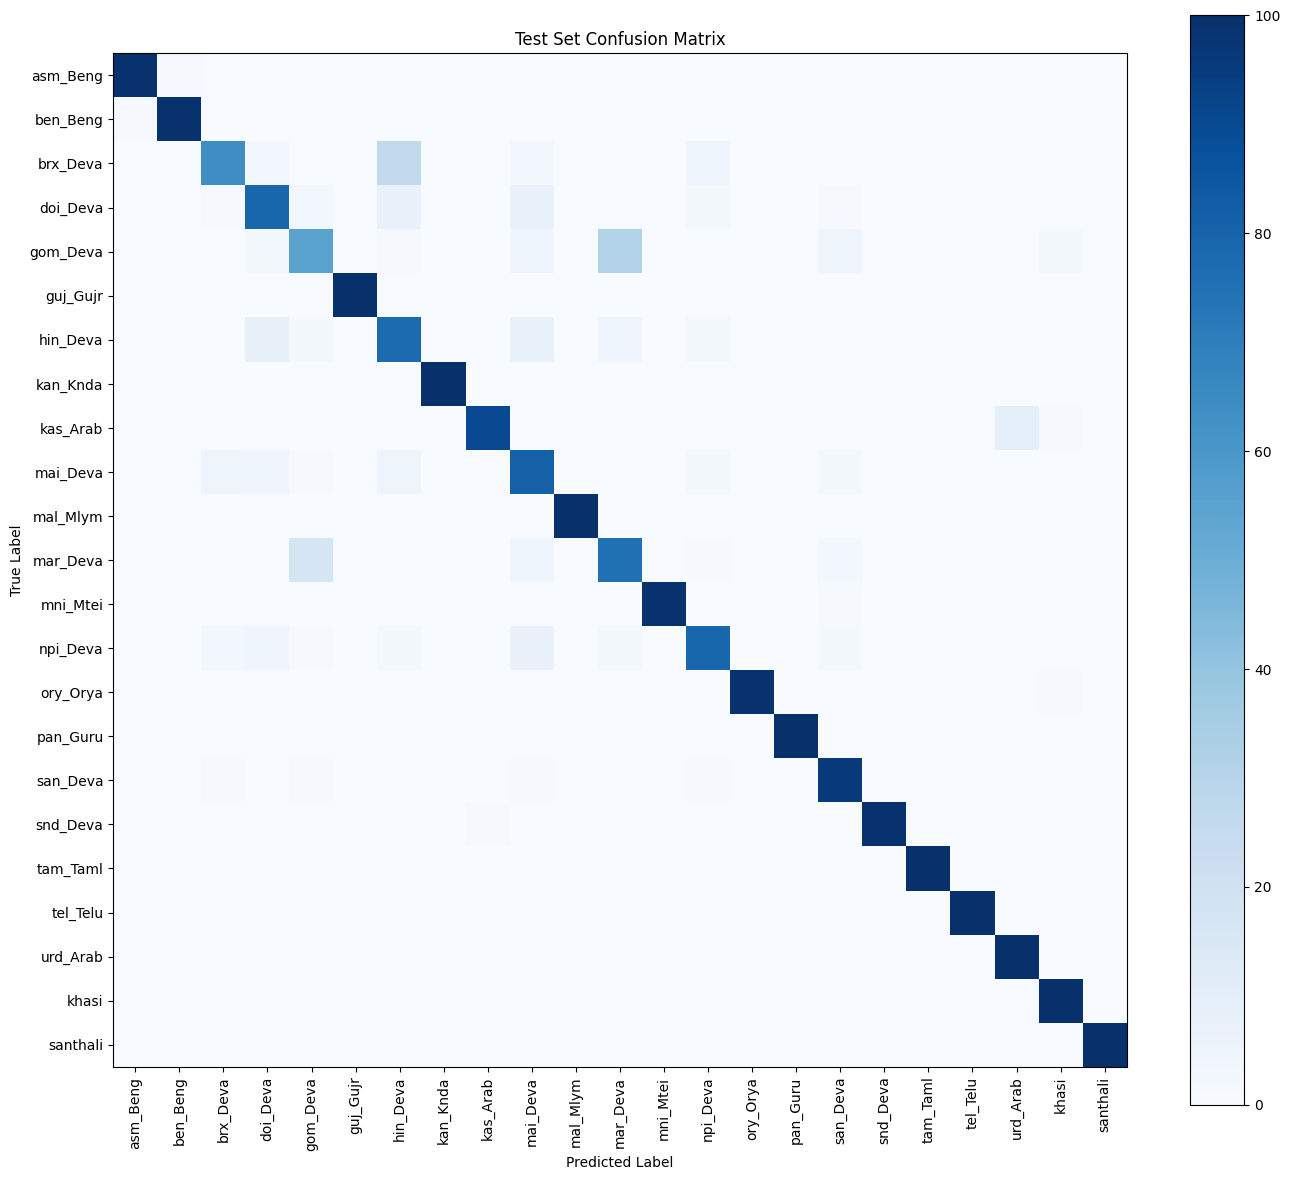

In [12]:
import matplotlib.pyplot as plt

n_classes = len(classes)
test_cm = compute_confusion_matrix(y_test, test_preds, n_classes)

plt.figure(figsize=(14, 12))
plt.imshow(test_cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("Test Set Confusion Matrix")
plt.colorbar()
tick_marks = np.arange(n_classes)
plt.xticks(tick_marks, classes, rotation=90)
plt.yticks(tick_marks, classes)
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()


## Summary & Error Analysis

### Final Results
- **Number of languages:** 23
- **Samples per language:** 1000
- **Split:** 800 train / 100 validation / 100 test per language
- **TF-IDF features:** word 1-grams + word 2-grams + character 2/3/4-grams
- **Classifier:** custom multiclass softmax logistic regression
- **Evaluation:** custom macro-F1 (no sklearn metric/classifier/vectorizer)

The actual values below are filled when the notebook is executed:
- Best hyperparameters: `best_params`
- Validation Macro-F1: `best_hyper_f1`
- Test Macro-F1: `final_test_f1`
- Test Accuracy: `final_test_acc`

### Error Analysis
Inspect the confusion matrix above. Languages sharing the same script can be harder to distinguish because their character n-grams overlap substantially. The combination of word n-grams and character n-grams lets the classifier use both lexical information and script/subword patterns.

> Note: the assignment requires macro-F1 and prohibits predefined sklearn classes for the vectorizer, logistic regression classifier, and evaluation. The notebook therefore implements all three components manually.
